In [1]:
import os
import random
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from sklearn.metrics import confusion_matrix
import seaborn as sns

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"--> Thiết bị sử dụng: {device}")

BATCH_SIZE = 128
NUM_CLASSES = 7
CLASSES = ['Angry', 'Disgust', 'Fear', 'Happy', 'Neutral', 'Sad', 'Surprise']

# Data Augmentation tương đương ImageDataGenerator trong tài liệu
train_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.RandomRotation(degrees=10),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(degrees=0, translate=(0.1, 0.1)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

test_transform = transforms.Compose([
    transforms.Grayscale(num_output_channels=1),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5], std=[0.5])
])

TRAIN_DIR = r"../data/raw/train"
TEST_DIR = r"../data/raw/test"

train_dataset = datasets.ImageFolder(root=TRAIN_DIR, transform=train_transform)
test_dataset = datasets.ImageFolder(root=TEST_DIR, transform=test_transform)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

print(f"Tổng số ảnh Train: {len(train_dataset)} | Test: {len(test_dataset)}")

--> Thiết bị sử dụng: cpu
Tổng số ảnh Train: 28709 | Test: 7178


In [2]:
# 1. SMALL CNN: 2 Conv block 1, 2 Conv block 2, 2 Conv block 3
class SmallCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(SmallCNN, self).__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2), nn.Dropout(0.2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 128, kernel_size=3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 256, kernel_size=3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2), nn.Dropout(0.2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 12 * 12, 1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

# 2. MEDIUM-01 CNN: 3 Conv block 1, 4 Conv block 2, 4 Conv block 3
class Medium01CNN(nn.Module):
    def __init__(self, num_classes=7):
        super(Medium01CNN, self).__init__()
        self.features = nn.Sequential(
            # Block 1: 48x48 -> 24x24
            nn.Conv2d(1, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.Conv2d(64, 64, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2), nn.Dropout(0.2),

            # Block 2: 24x24 -> 12x12
            nn.Conv2d(64, 128, 3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(),
            nn.Conv2d(128, 128, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2), nn.Dropout(0.2),

            # Block 3: 12x12 -> 6x6
            nn.Conv2d(128, 256, 3, padding=1), nn.ReLU(),
            nn.Conv2d(256, 256, 3, padding=1), nn.ReLU(),
            nn.Conv2d(256, 256, 3, padding=1), nn.ReLU(),
            nn.MaxPool2d(2, 2), nn.Dropout(0.2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 6 * 6, 1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, num_classes)
        )
    def forward(self, x):
        return self.classifier(self.features(x))

model_small = SmallCNN().to(device)
model_medium = Medium01CNN().to(device)
print("Khởi tạo SmallCNN và Medium01CNN thành công!")

Khởi tạo SmallCNN và Medium01CNN thành công!


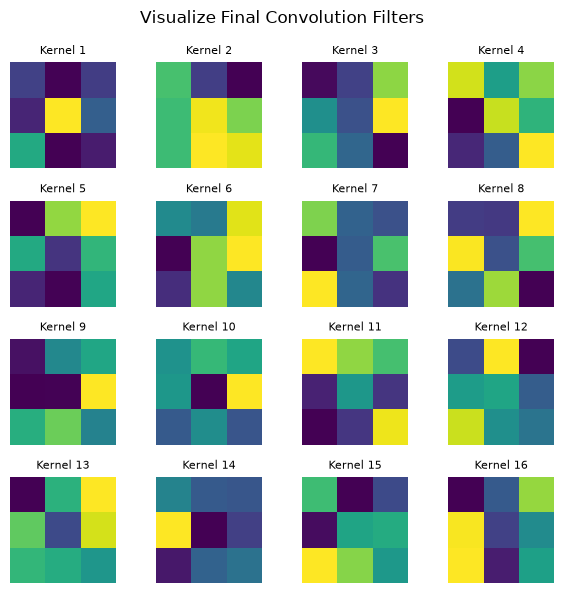

--> Đã lưu hình ảnh bộ lọc tích chập vào ../results/plots/final_conv_filters.png


In [3]:
def visualize_conv_filters(layer, num_filters=16, save_path="../results/plots/final_conv_filters.png"):
    weights = layer.weight.data.cpu()
    fig, axes = plt.subplots(4, 4, figsize=(6, 6))
    for i, ax in enumerate(axes.flat):
        if i < num_filters:
            # Lấy kênh đầu tiên của kernel
            filt = weights[i, 0, :, :].numpy()
            filt = (filt - filt.min()) / (filt.max() - filt.min() + 1e-8)
            ax.imshow(filt, cmap="viridis")
            ax.set_title(f"Kernel {i+1}", fontsize=8)
        ax.axis("off")
    plt.suptitle("Visualize Final Convolution Filters", fontsize=12)
    plt.tight_layout()
    os.makedirs(os.path.dirname(save_path), exist_ok=True)
    plt.savefig(save_path, dpi=300)
    plt.show()
    print(f"--> Đã lưu hình ảnh bộ lọc tích chập vào {save_path}")

# Hiển thị bộ lọc của tầng Conv cuối cùng trong Block 3 của Medium01CNN
last_conv_layer = model_medium.features[10] # Tầng Conv2d cuối cùng
visualize_conv_filters(last_conv_layer)

--> Đã nạp thành công trọng số từ: ../checkpoints/baseline_best.pth
Tổng số ảnh kiểm tra: 7178
Số lượng mẫu đoán đúng: 3470 (48.34%)
Số lượng mẫu đoán sai: 3708 (51.66%)


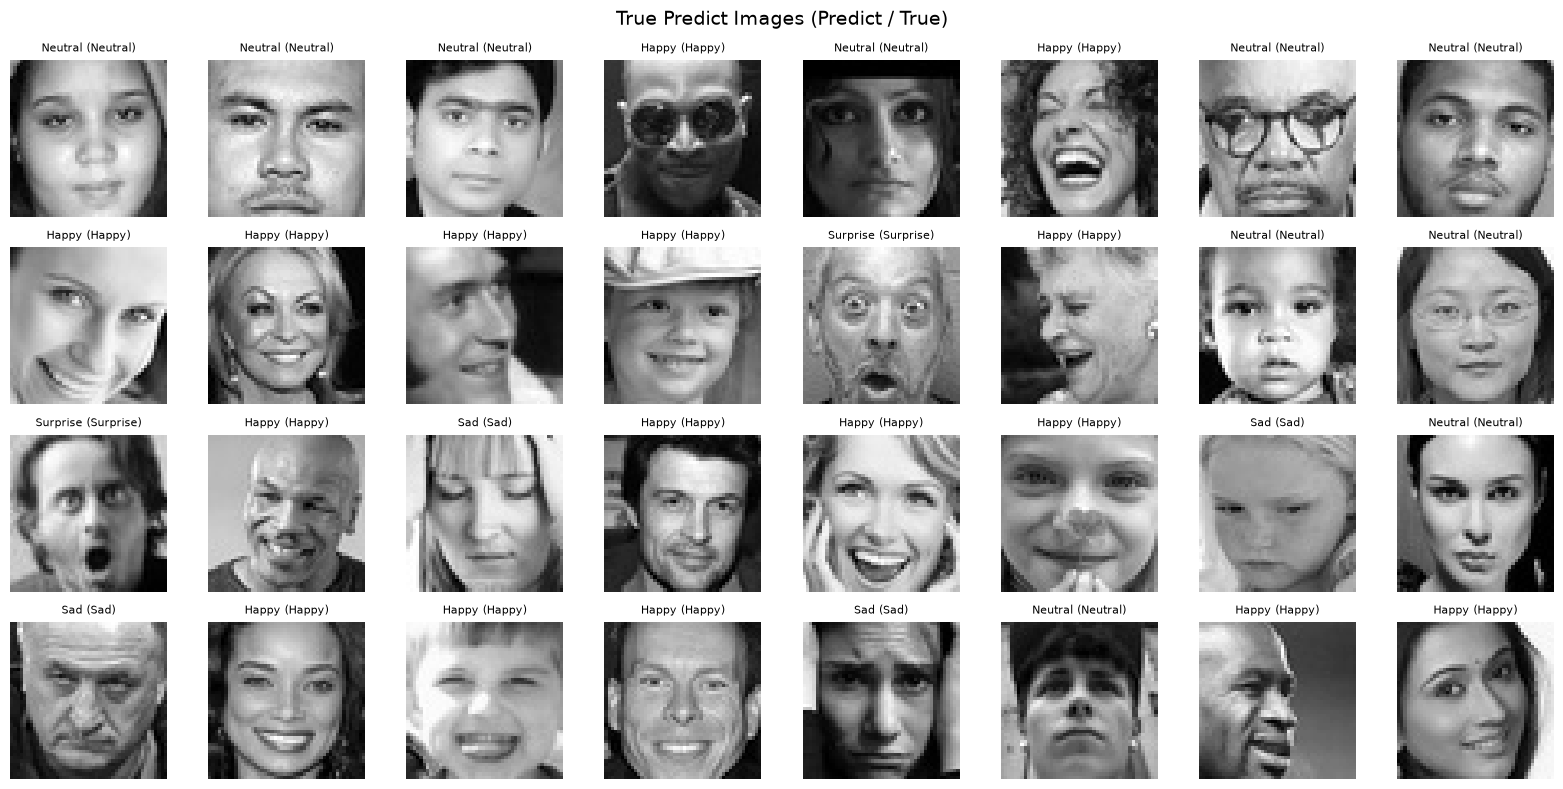

--> Đã lưu hình ảnh vào ../results/plots/true_predict_images.png


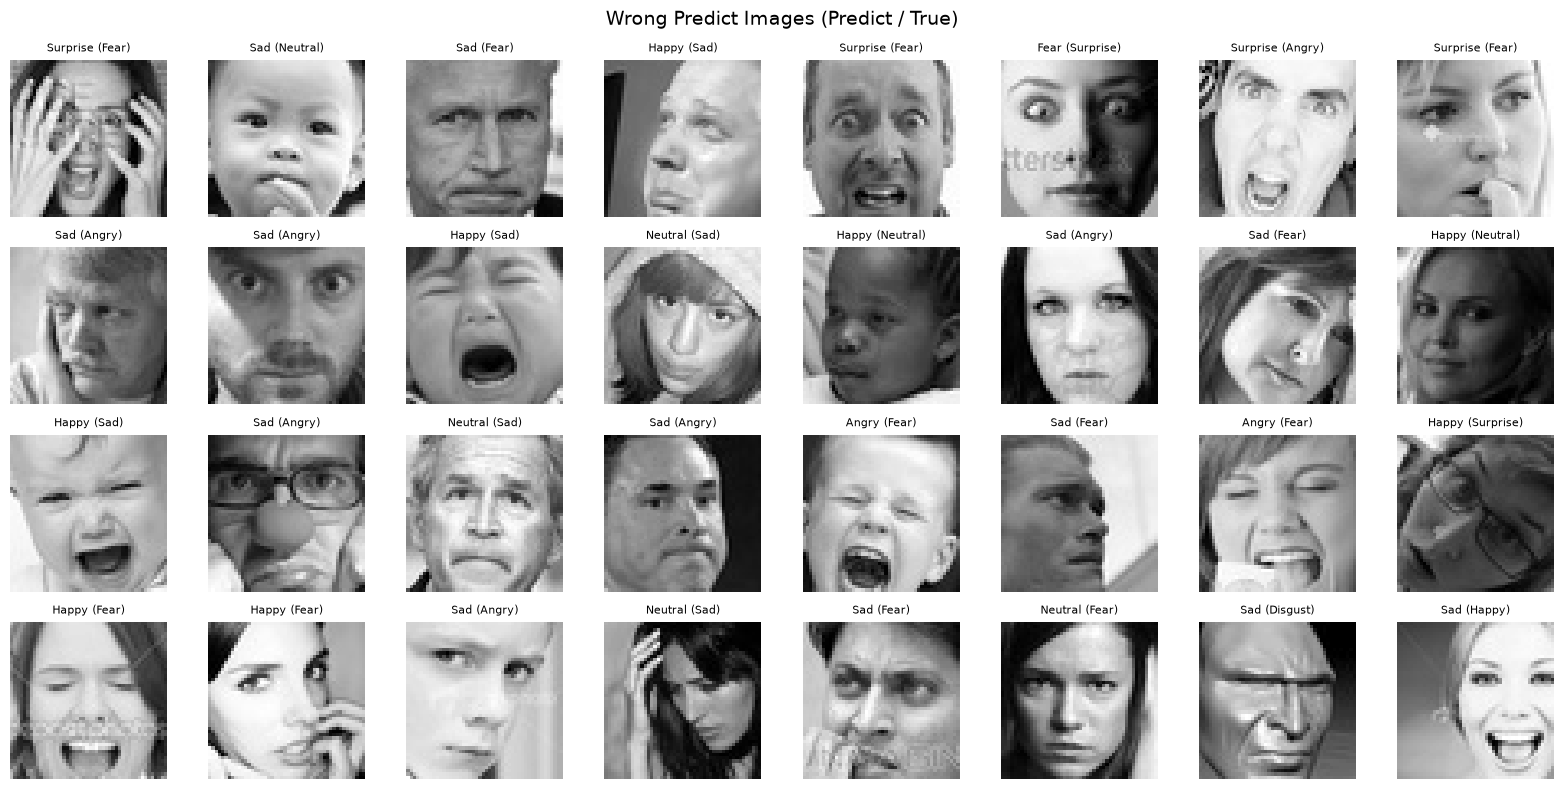

--> Đã lưu hình ảnh vào ../results/plots/wrong_predict_images.png


In [5]:
# Tái định nghĩa kiến trúc Baseline để load checkpoint
class BaselineCNN(nn.Module):
    def __init__(self, num_classes=7):
        super(BaselineCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 32, kernel_size=3, padding=1)
        self.bn1 = nn.BatchNorm2d(32)
        self.relu = nn.ReLU()
        self.pool = nn.MaxPool2d(2, 2)
        
        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.bn2 = nn.BatchNorm2d(64)
        
        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.bn3 = nn.BatchNorm2d(128)
        
        self.fc1 = nn.Linear(128 * 6 * 6, 256)
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool(self.relu(self.bn1(self.conv1(x))))
        x = self.pool(self.relu(self.bn2(self.conv2(x))))
        x = self.pool(self.relu(self.bn3(self.conv3(x))))
        x = x.view(x.size(0), -1)
        x = self.dropout(self.relu(self.fc1(x)))
        x = self.fc2(x)
        return x

# Khởi tạo mô hình và nạp trọng số đã lưu
eval_model = BaselineCNN(num_classes=NUM_CLASSES).to(device)
best_model_path = "../checkpoints/baseline_best.pth"

if os.path.exists(best_model_path):
    eval_model.load_state_dict(torch.load(best_model_path, map_location=device))
    print(f"--> Đã nạp thành công trọng số từ: {best_model_path}")
else:
    print(f"--> Không tìm thấy file {best_model_path}, đang dùng trọng số ngẫu nhiên!")

eval_model.eval()

# Đánh giá và thu thập kết quả dự đoán
all_images, all_preds, all_labels = [], [], []

with torch.no_grad():
    for images, labels in test_loader:
        images_dev = images.to(device)
        outputs = eval_model(images_dev)
        _, preds = torch.max(outputs, 1)
        
        all_images.extend(images.cpu())
        all_preds.extend(preds.cpu().numpy())
        all_labels.extend(labels.numpy())

all_preds = np.array(all_preds)
all_labels = np.array(all_labels)

# Xác định chỉ mục các mẫu đoán đúng và đoán sai
true_indices = np.where(all_preds == all_labels)[0]
wrong_indices = np.where(all_preds != all_labels)[0]

print(f"Tổng số ảnh kiểm tra: {len(all_labels)}")
print(f"Số lượng mẫu đoán đúng: {len(true_indices)} ({len(true_indices)/len(all_labels)*100:.2f}%)")
print(f"Số lượng mẫu đoán sai: {len(wrong_indices)} ({len(wrong_indices)/len(all_labels)*100:.2f}%)")

# Hàm vẽ lưới 32 ảnh kèm nhãn (Predict / True) chuẩn mẫu báo cáo
def plot_case_grid(indices, title, save_file):
    selected = random.sample(list(indices), min(32, len(indices)))
    fig, axes = plt.subplots(4, 8, figsize=(16, 8))
    for idx, ax in zip(selected, axes.flat):
        img = all_images[idx].squeeze().numpy()
        pred_name = CLASSES[all_preds[idx]]
        true_name = CLASSES[all_labels[idx]]
        ax.imshow(img, cmap="gray")
        ax.set_title(f"{pred_name} ({true_name})", fontsize=8)
        ax.axis("off")
    plt.suptitle(title, fontsize=14)
    plt.tight_layout()
    os.makedirs("../results/plots", exist_ok=True)
    plt.savefig(f"../results/plots/{save_file}", dpi=300)
    plt.show()
    print(f"--> Đã lưu hình ảnh vào ../results/plots/{save_file}")

# Xuất 2 hình ảnh phục vụ mục 3.4 & 3.5 của báo cáo
plot_case_grid(true_indices, "True Predict Images (Predict / True)", "true_predict_images.png")
plot_case_grid(wrong_indices, "Wrong Predict Images (Predict / True)", "wrong_predict_images.png")

In [6]:
import torchvision.models as models

class VGG16_FailCase(nn.Module):
    def __init__(self, num_classes=7):
        super(VGG16_FailCase, self).__init__()
        # Lấy kiến trúc VGG16 gốc không pretrain
        base_vgg = models.vgg16(weights=None)
        self.features = base_vgg.features
        # Đổi input kênh đầu từ 3 thành 1 cho ảnh grayscale 48x48
        self.features[0] = nn.Conv2d(1, 64, kernel_size=3, padding=1)
        
        # Với 5 lần MaxPool2d (chia đôi 5 lần): 48 -> 24 -> 12 -> 6 -> 3 -> 1
        # Kích thước feature map cuối chỉ còn 1x1x512 = 512
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(512 * 1 * 1, 1024),
            nn.ReLU(),
            nn.Dropout(0.5),
            nn.Linear(1024, num_classes)
        )
        
    def forward(self, x):
        return self.classifier(self.features(x))

fail_vgg = VGG16_FailCase(num_classes=NUM_CLASSES).to(device)
print(fail_vgg)

VGG16_FailCase(
  (features): Sequential(
    (0): Conv2d(1, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU(inplace=True)
    (2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (3): ReLU(inplace=True)
    (4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (5): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (6): ReLU(inplace=True)
    (7): Conv2d(128, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (8): ReLU(inplace=True)
    (9): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (10): Conv2d(128, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (11): ReLU(inplace=True)
    (12): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (13): ReLU(inplace=True)
    (14): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (15): ReLU(inplace=True)
    (16): MaxPool2d(kernel_size=2, stride=2, padding=0,

--- THỰC NGHIỆM FAIL CASE VGG16 (3 EPOCHS) ---
Epoch [1/3] - Train Loss: 1.7959 - Test Acc: 26.83%
Epoch [2/3] - Train Loss: 1.6669 - Test Acc: 42.02%
Epoch [3/3] - Train Loss: 1.4882 - Test Acc: 44.30%


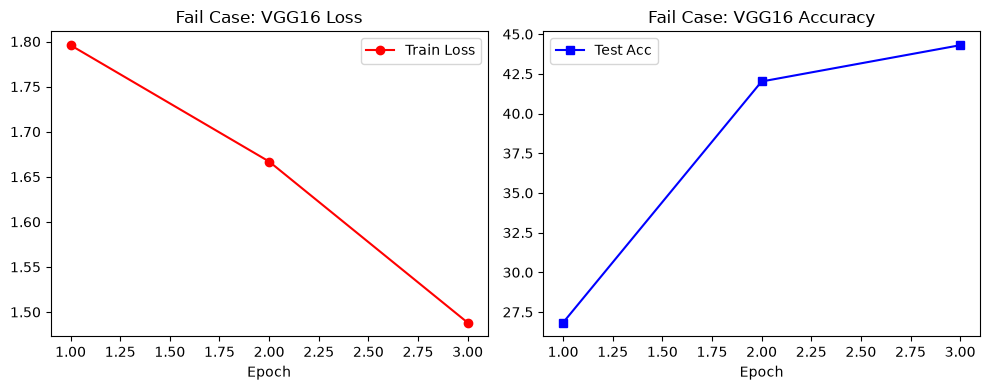

--> Đã lưu biểu đồ vào results/plots/vgg16_fail_curve.png


In [7]:
fail_criterion = nn.CrossEntropyLoss()
fail_optimizer = optim.Adam(fail_vgg.parameters(), lr=0.0001)

fail_train_losses = []
fail_test_accs = []

print("--- THỰC NGHIỆM FAIL CASE VGG16 (3 EPOCHS) ---")
for epoch in range(3):
    fail_vgg.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        fail_optimizer.zero_grad()
        outputs = fail_vgg(images)
        loss = fail_criterion(outputs, labels)
        loss.backward()
        fail_optimizer.step()
        running_loss += loss.item() * images.size(0)
        
    epoch_loss = running_loss / len(train_dataset)
    fail_train_losses.append(epoch_loss)
    
    fail_vgg.eval()
    correct, total = 0, 0
    with torch.no_grad():
        for images, labels in test_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = fail_vgg(images)
            _, preds = torch.max(outputs, 1)
            total += labels.size(0)
            correct += (preds == labels).sum().item()
            
    acc = 100.0 * correct / total
    fail_test_accs.append(acc)
    print(f"Epoch [{epoch+1}/3] - Train Loss: {epoch_loss:.4f} - Test Acc: {acc:.2f}%")

# Vẽ biểu đồ đối chiếu Fail Case
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.plot(range(1, 4), fail_train_losses, 'r-o', label='Train Loss')
plt.title('Fail Case: VGG16 Loss')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(range(1, 4), fail_test_accs, 'b-s', label='Test Acc')
plt.title('Fail Case: VGG16 Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.savefig("../results/plots/vgg16_fail_curve.png", dpi=300)
plt.show()
print("--> Đã lưu biểu đồ vào results/plots/vgg16_fail_curve.png")